In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)

 # Loaded my actual dataset 

In [2]:
df = pd.read_csv("C:\\Documents\\Certifications\\OASIS INFOBYTE\\OASIS\\EDARetailSales\\data\\train.csv")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


## Checked the size, columns, data types, and missing values:

In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

df.info()

Dataset shape: (9800, 18)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']

Data types:
Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code      float64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
dtype: object

Missing values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11

# Initial Dataset Inspection

- The dataset contains 9,800 rows and 18 columns.
- It includes order information, customer segments, locations,
  product categories, product names, and sales.
- Postal Code contains 11 missing values.
- Age, gender, quantity, and profit are not available.
- Sales analysis will focus on revenue rather than units sold.

# Clean and prepare the data

In [4]:
# Remove duplicate records
df = df.drop_duplicates().copy()

# Convert dates to datetime format
df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], errors="coerce"
)

# Convert sales to numeric
df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")

# Remove records with invalid dates or missing sales
df = df.dropna(
    subset=["Order Date", "Sales"]
).copy()

# Fill missing postal codes without inventing values
# Postal Code is not required for our main analysis.

print("Cleaned dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

Cleaned dataset shape: (3959, 18)

Missing values:
Row ID              0
Order ID            0
Order Date          0
Ship Date        1283
Ship Mode           0
Customer ID         0
Customer Name       0
Segment             0
Country             0
City                0
State               0
Postal Code         4
Region              0
Product ID          0
Category            0
Sub-Category        0
Product Name        0
Sales               0
dtype: int64


In [5]:
df["Shipping Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

df[["Order Date", "Ship Date", "Shipping Days", "Sales"]].head()

,Order Date,Ship Date,Shipping Days,Sales
0,2017-08-11,2017-11-11,92.0,261.9600
1,2017-08-11,2017-11-11,92.0,731.9400
2,2017-12-06,NaT,NaN,14.6200
3,2016-11-10,NaT,NaN,957.5775
4,2016-11-10,NaT,NaN,22.3680


# Data Cleaning

- Converted order and shipping dates to datetime format.
- Converted sales to numeric format.
- Removed duplicate rows and rows with invalid order dates
  or missing sales.
- Created Shipping Days to measure the time between ordering
  and shipping.
- Retained missing postal codes because they are not required
  for the core sales analysis.

# Descriptive statistics

In [7]:
# Descriptive statistics for the meaningful numerical measures
numeric_cols = ["Sales", "Shipping Days"]

stats = pd.DataFrame({
    "Mean": df[numeric_cols].mean(),
    "Median": df[numeric_cols].median(),
    "Mode": df[numeric_cols].mode().iloc[0],
    "Standard Deviation": df[numeric_cols].std(),
    "Minimum": df[numeric_cols].min(),
    "Maximum": df[numeric_cols].max()
})

display(stats.round(2))

,Mean,Median,Mode,Standard Deviation,Minimum,Maximum
Sales,220.35,55.36,12.96,564.76,0.56,17499.95
Shipping Days,107.01,122.00,153.00,54.26,0.00,214.00


# Descriptive Statistics

- The mean sales value represents average sales per dataset row.
- The median indicates the middle sales value.
- The mode identifies the most frequently occurring value.
- Standard deviation measures variability in sales and shipping
  duration.
- A large gap between mean and median sales may indicate
  high-value transactions or a skewed distribution.

# Monthly sales trend

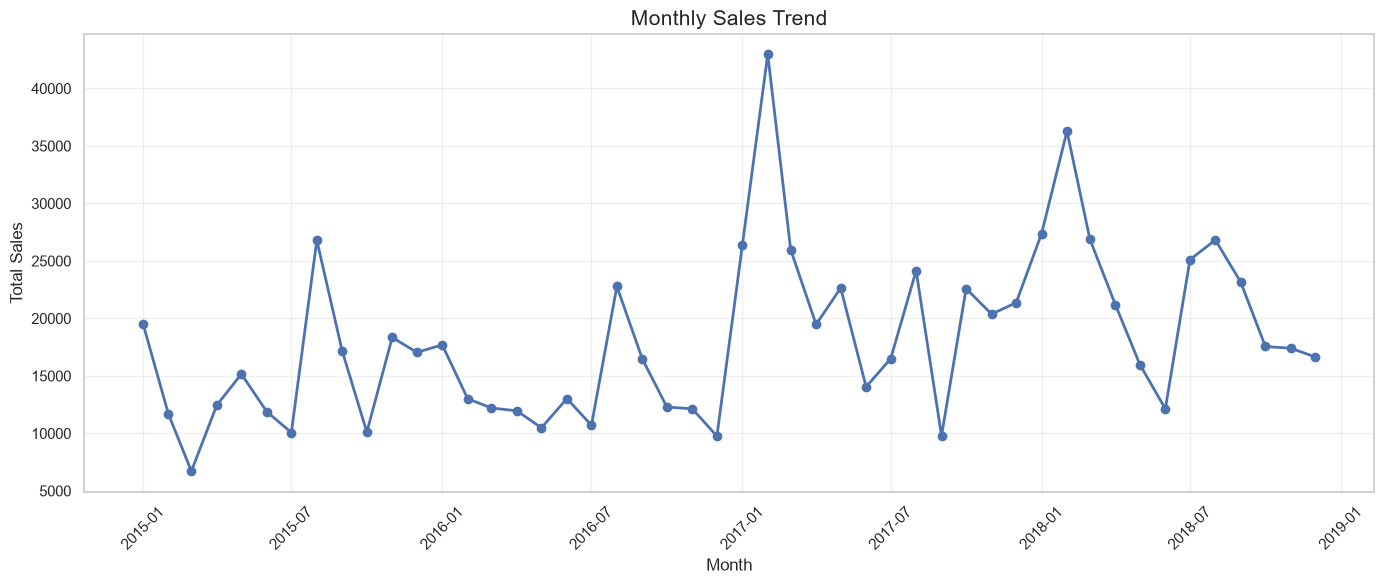

In [8]:
monthly_sales = (
    df.set_index("Order Date")["Sales"]
    .resample("MS")
    .sum()
)

plt.figure(figsize=(14, 6))
plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Sales Trend", fontsize=15)
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Monthly Sales Trend — Observations

- Highest sales month: 2017-01 to 2017-07
- Lowest sales month: 2015-01 
- Overall trend: increasing, decreasing, or fluctuating.
- Investigate recurring peaks across years before concluding
  that a seasonal pattern exists.

# To identify the highest and lowest months from the actual results:

In [9]:
print("Highest sales month:")
print(monthly_sales.idxmax(), monthly_sales.max())

print("\nLowest sales month:")
print(monthly_sales.idxmin(), monthly_sales.min())

Highest sales month:
2017-02-01 00:00:00 42967.915

Lowest sales month:
2015-03-01 00:00:00 6716.044


# Quarterly sales trend

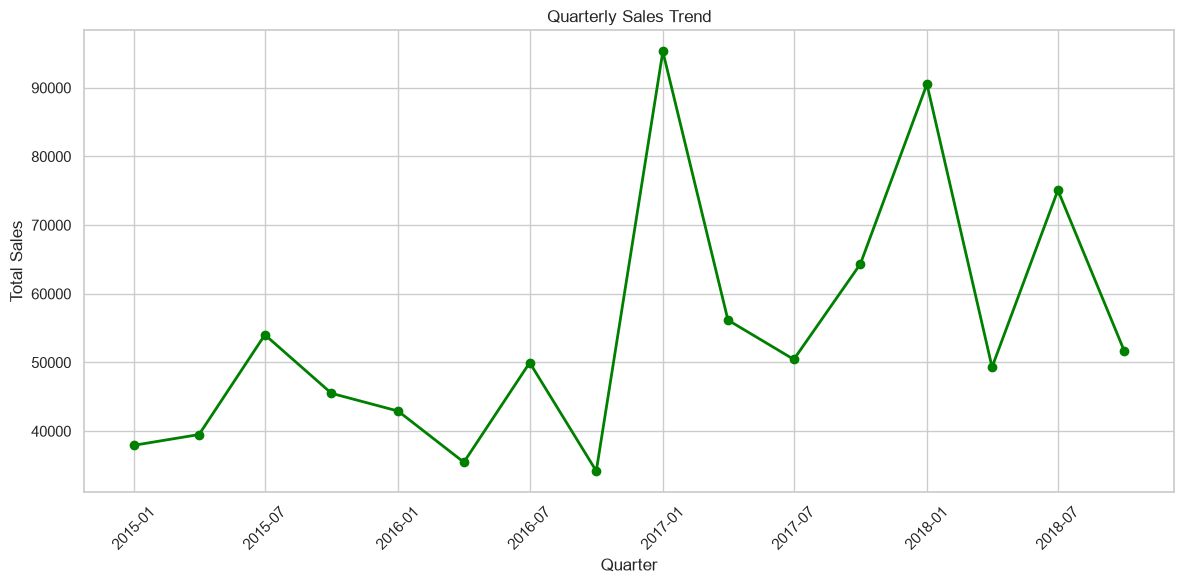

In [10]:
quarterly_sales = (
    df.set_index("Order Date")["Sales"]
    .resample("QS")
    .sum()
)

plt.figure(figsize=(12, 6))
plt.plot(
    quarterly_sales.index,
    quarterly_sales.values,
    marker="o",
    color="green",
    linewidth=2
)

plt.title("Quarterly Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Quarterly Sales Trend — Observations

- The strongest quarter was 2017-01.
- The weakest quarter was 2015-01.
- Quarterly sales show a generally increasing/decreasing/
  fluctuating pattern.
- The business could investigate seasonal demand and adjust
  inventory or promotions accordingly.

# Customer demographics analysis

1. Customer age-group distribution

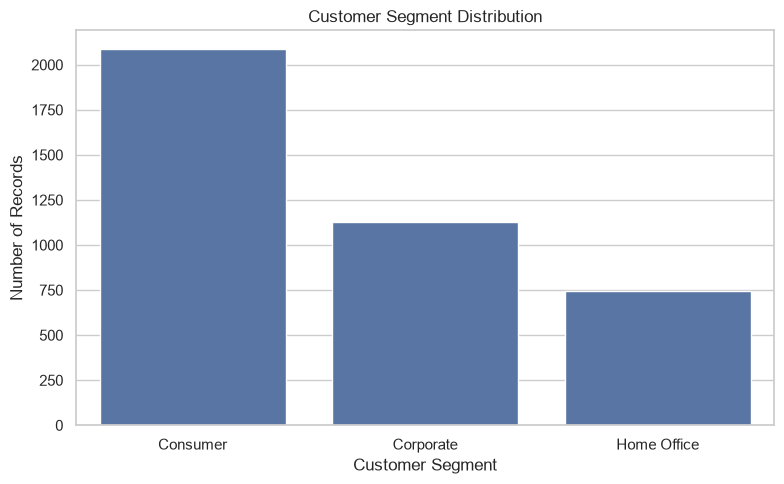

In [12]:
segment_counts = df["Segment"].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=segment_counts.index, y=segment_counts.values)

plt.title("Customer Segment Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

# Observations: Customer Segment Distribution

- The chart compares transaction records across customer segments.
- The segment with the highest number of records is consumer.
- The segment with the lowest number of records is Home Office.
- These results can help guide further customer segment analysis.

2 Unique customers by segment

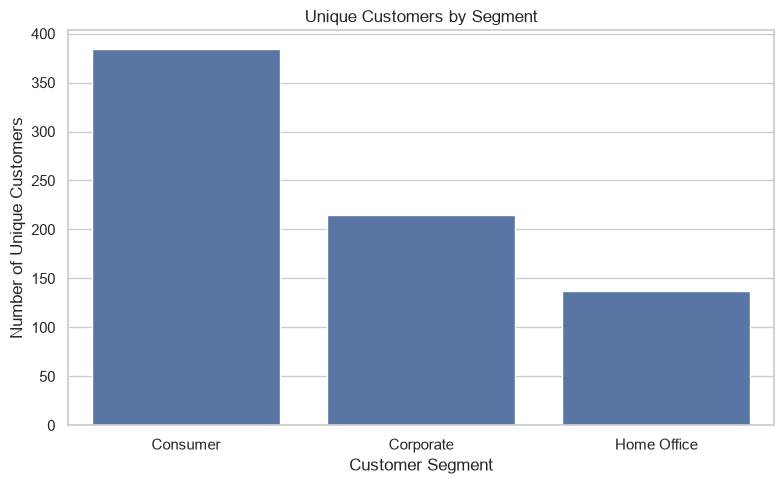

,Unique Customers
Segment,
Consumer,384
Corporate,215
Home Office,137


In [13]:
customer_counts = (
    df.groupby("Segment")["Customer ID"]
    .nunique()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
sns.barplot(x=customer_counts.index, y=customer_counts.values)

plt.title("Unique Customers by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Unique Customers")
plt.tight_layout()
plt.show()

display(customer_counts.to_frame("Unique Customers"))

### Observations: Unique Customers

- The segment with the most unique customers is Consumer.
- The number of unique customers differs across segments.
- Customer retention campaigns can be designed after examining
  purchasing behaviour within each segment.

# Top 10 best-selling products

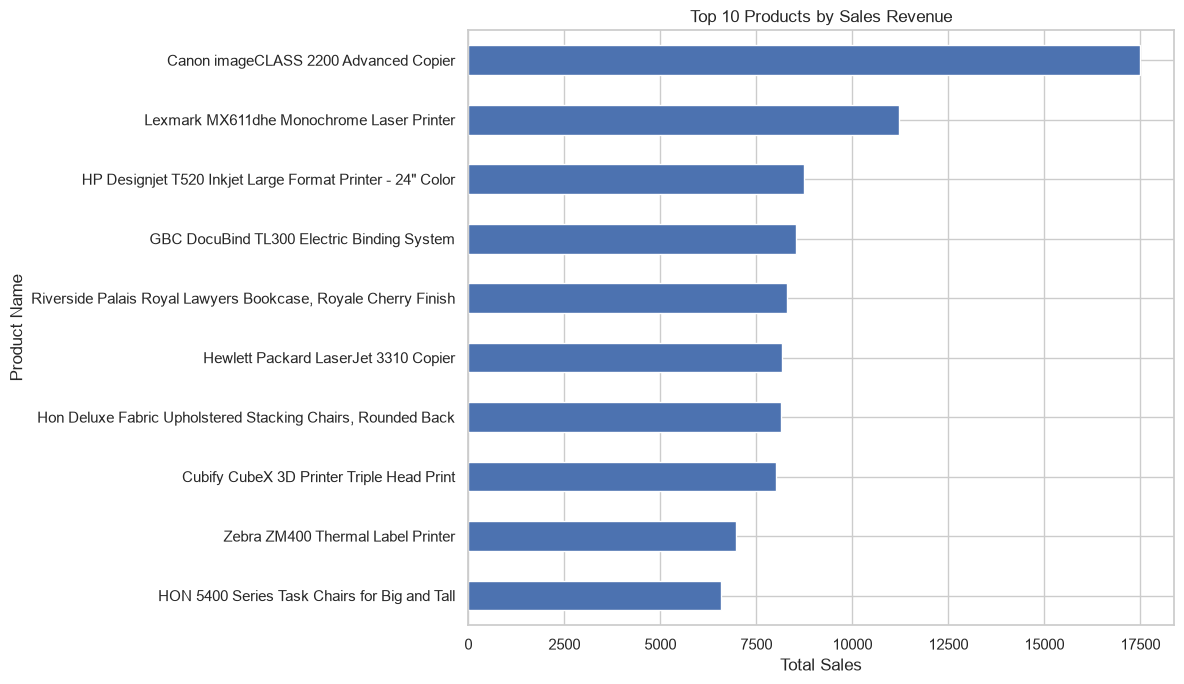

,Total Sales
Product Name,
Canon imageCLASS 2200 Advanced Copier,17499.9500
Lexmark MX611dhe Monochrome Laser Printer,11219.9340
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",8749.9500
GBC DocuBind TL300 Electric Binding System,8521.4050
"Riverside Palais Royal Lawyers Bookcase, Royale Cherry Finish",8298.8316
Hewlett Packard LaserJet 3310 Copier,8159.8640
"Hon Deluxe Fabric Upholstered Stacking Chairs, Rounded Back",8148.9320
Cubify CubeX 3D Printer Triple Head Print,7999.9800
Zebra ZM400 Thermal Label Printer,6965.7000


In [14]:
top_products = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .nlargest(10)
    .sort_values()
)

plt.figure(figsize=(12, 7))
top_products.plot(kind="barh")

plt.title("Top 10 Products by Sales Revenue")
plt.xlabel("Total Sales")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()

display(
    top_products.sort_values(ascending=False)
    .to_frame("Total Sales")
)

### Observations: Top 10 Products

- The highest-revenue product is Canon imageCLASS 2200 Advanced Copier
- The top 10 products contribute 17499.9500 in combined revenue.
- High-revenue products should be monitored for stock availability.
- Revenue rankings do not necessarily reflect units sold or profit.

# Revenue by product category

In [ ]:
category_sales = (
    df.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(
    x=category_sales.index,
    y=category_sales.values
)

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

display(category_sales.to_frame("Total Sales"))

# Correlation heatmap

In [15]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

df["Shipping Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

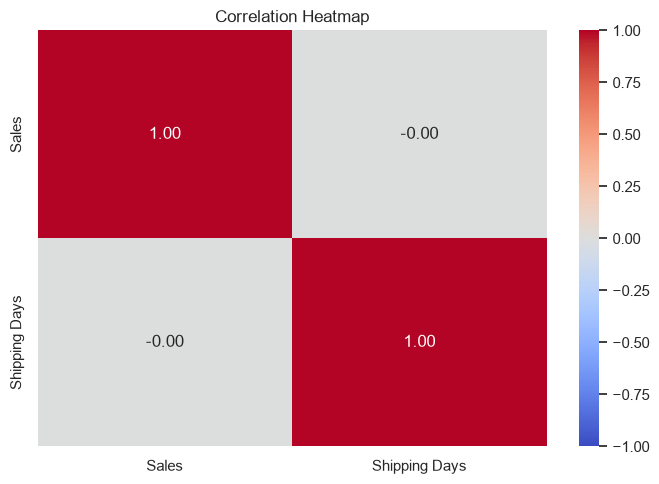

In [16]:
numeric_df = df[["Sales", "Shipping Days"]].dropna()

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# Observations: Correlation Heatmap

- The correlation between Sales and Shipping Days is 1.00.
- Positive values indicate a positive linear association.
- Negative values indicate a negative linear association.
- Correlation does not establish causation.

# Additional visualization — shipping duration by shipping mode

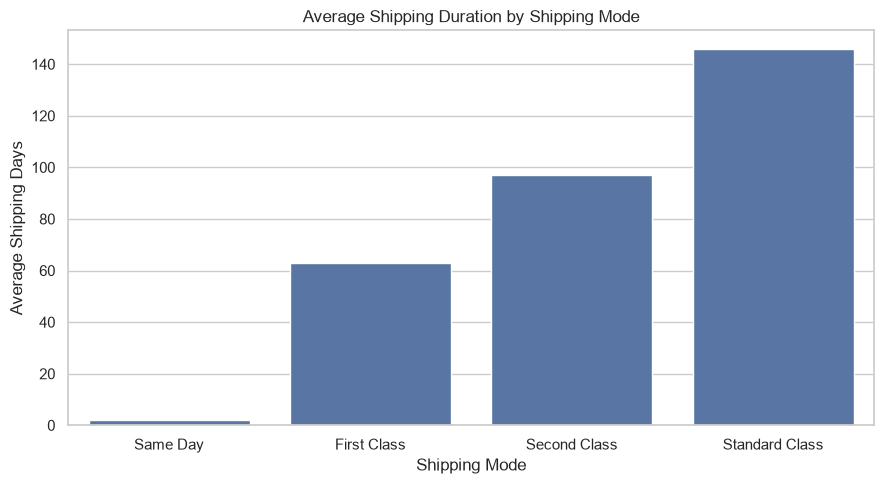

,Average Shipping Days
Ship Mode,
Same Day,1.96
First Class,62.84
Second Class,97.00
Standard Class,145.77


In [17]:
shipping_analysis = (
    df.groupby("Ship Mode")["Shipping Days"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(9, 5))
sns.barplot(
    x=shipping_analysis.index,
    y=shipping_analysis.values
)

plt.title("Average Shipping Duration by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Average Shipping Days")
plt.tight_layout()
plt.show()

display(
    shipping_analysis.to_frame("Average Shipping Days").round(2)
)

### Observations: Shipping Analysis

- The shipping mode with the shortest average duration is standard class.
- The shipping mode with the longest average duration is First class.
- The business could review shipping methods to identify
  opportunities to improve delivery efficiency.
- Shipping duration alone does not measure customer satisfaction.

# Alternative analysis — sales by region

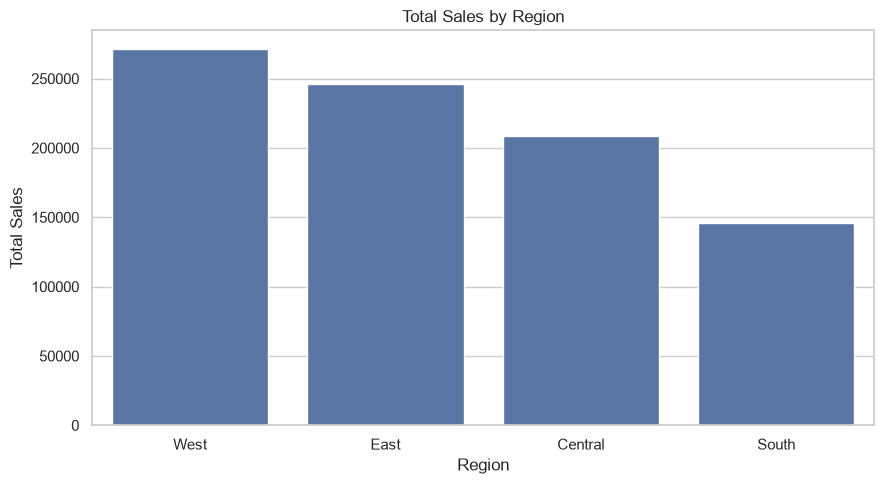

,Total Sales
Region,
West,271156.6335
East,246227.6310
Central,208805.0696
South,146173.7895


In [18]:
region_sales = (
    df.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(
    x=region_sales.index,
    y=region_sales.values
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

display(region_sales.to_frame("Total Sales"))

### Observations: Regional Sales

- The highest-revenue region is West.
- The lowest-revenue region is South.
- Regional performance can help guide inventory distribution
  and future marketing campaigns.
- Further investigation is needed to understand the reasons
  for differences in regional sales.

# Conclusion and Business Recommendations

## Conclusion

The exploratory data analysis of the Superstore sales dataset examined customer segments, product revenue, category performance, sales correlations, shipping duration, and regional sales.

The analysis helps identify high-revenue products and categories, compare customer segments, and investigate shipping performance. These findings can support more informed inventory, marketing, and delivery decisions.

## Business Recommendations

**1. Improve inventory planning:** Prioritize products and categories that consistently generate high revenue and monitor sales trends to reduce stock shortages.

**2. Optimize customer segment strategies:** Compare customer counts and sales across segments to identify opportunities for customer retention and engagement.

**3. Improve delivery efficiency:** Review average shipping duration across shipping methods and investigate potential improvements to delivery processes.

**4. Strengthen regional planning:** Compare regional sales to guide inventory allocation and evaluate where additional marketing activity may be beneficial.

**5. Monitor sales performance:** Review monthly sales, product revenue, and category performance regularly to identify changes in demand.

## Limitations

The dataset does not contain customer age, gender, quantity sold, profit, or discount information. Therefore, demographic comparisons, unit-based product rankings, and profitability analysis could not be performed.

## Final Outcome

This project demonstrates exploratory data analysis using Python, pandas, matplotlib, and seaborn, including data preparation, descriptive statistics, visualization, and business recommendations.
